In [1]:
import sys

sys.path.insert(0, "/home/dev/simcc/lib")

In [2]:
from dataset import coco

In [3]:
class Arg(object):
    def __init__(self):
        self.cfg = "/home/dev/simcc/experiments/coco/resnet/simdr/upsample_free/nmt_res50_256x192_d256x3_adam_lr1e-3_split_2_cpj28.yaml"
        self.opts = []
        self.modelDir = ""
        self.logDir = ""
        self.dataDir = ""
        self.prevModelDir = ""

In [4]:
args = Arg()

In [5]:
from config import cfg
from config import update_config

In [6]:
update_config(cfg, args)

In [7]:
cfg

CfgNode({'OUTPUT_DIR': 'output', 'LOG_DIR': 'log', 'DATA_DIR': '', 'GPUS': (0,), 'WORKERS': 24, 'PRINT_FREQ': 100, 'AUTO_RESUME': True, 'PIN_MEMORY': True, 'RANK': 0, 'CUDNN': CfgNode({'BENCHMARK': True, 'DETERMINISTIC': False, 'ENABLED': True}), 'MODEL': CfgNode({'NAME': 'pose_resnet_upfree', 'INIT_WEIGHTS': True, 'PRETRAINED': 'data/pretrained/imagenet/resnet50-19c8e357.pth', 'NUM_JOINTS': 17, 'TAG_PER_JOINT': True, 'IMAGE_SIZE': [192, 256], 'HEATMAP_SIZE': [192, 256], 'SIGMA': 1, 'COORD_REPRESENTATION': 'simdr', 'AUX_ALPHA': 1e-05, 'SIMDR_SPLIT_RATIO': 2.0, 'HEAD_INPUT': 1344, 'DIM': 2, 'INIT': False, 'EXTRA': CfgNode({'FINAL_CONV_KERNEL': 1, 'CHANNEL_PER_JOINT': 28, 'NUM_LAYERS': 50})}), 'LOSS': CfgNode({'USE_OHKM': False, 'TOPK': 8, 'USE_TARGET_WEIGHT': True, 'USE_DIFFERENT_JOINTS_WEIGHT': False, 'TYPE': 'NMTCritierion', 'LABEL_SMOOTHING': 0.1}), 'DATASET': CfgNode({'ROOT': 'data/dataset/coco', 'DATASET': 'coco', 'TRAIN_SET': 'train2017', 'TEST_SET': 'val2017', 'DATA_FORMAT': 'jpg

In [8]:
import torchvision.transforms as transforms

In [9]:
normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
)

In [10]:
"""
train_dataset = coco(
        cfg, cfg.DATASET.ROOT, cfg.DATASET.TRAIN_SET, True,
        transforms.Compose([
            transforms.ToTensor(),
            normalize,
        ]),
        cfg.MODEL.COORD_REPRESENTATION,
        cfg.MODEL.SIMDR_SPLIT_RATIO
    )
"""

train_dataset = coco(
        cfg, cfg.DATASET.ROOT, cfg.DATASET.TRAIN_SET, True,
        None,
        cfg.MODEL.COORD_REPRESENTATION,
        cfg.MODEL.SIMDR_SPLIT_RATIO
    )

loading annotations into memory...
Done (t=2.81s)
creating index...
index created!
++++++++++++++++++++++++++++++++++++++++++++


In [16]:
img, target, target_weight, meta = train_dataset[0]

In [17]:
type(img)

numpy.ndarray

In [19]:
img.shape

(256, 192, 3)

In [13]:
target

array([[286,  39],
       [  0,   0],
       [284,  22],
       [  0,   0],
       [259,  14],
       [156,  78],
       [286,  84],
       [134, 164],
       [298, 164],
       [  0,   0],
       [302, 219],
       [148, 244],
       [230, 246],
       [105, 377],
       [284, 297],
       [ 79, 480],
       [300, 400]])

In [21]:
%matplotlib inline

from PIL import Image
from IPython.display import display
from matplotlib import pyplot as plt

COLOR_MAGENTA = (255, 0, 255) # RGB
COLOR_CYAN = (0, 255, 255) # RGB
COLOR_YELLOW = (255, 255, 0) # RGB

In [25]:
meta.keys()

dict_keys(['image', 'filename', 'imgnum', 'joints', 'joints_vis', 'center', 'scale', 'rotation', 'score'])

In [26]:
meta['image']

'data/dataset/coco/images/train2017/000000391895.jpg'

In [48]:
import random
import cv2
from torchvision.io import read_image
from torchvision.transforms.v2 import ToPILImage

to_pil = ToPILImage()

In [28]:
len(train_dataset)

149813

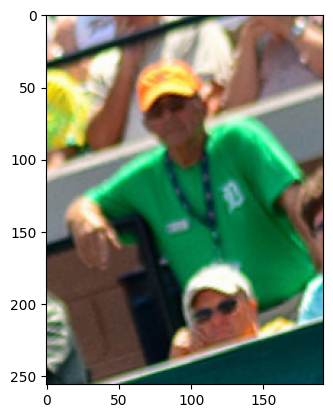

In [157]:
idx = random.randint(0,len(train_dataset))
img, target, target_weight, meta = train_dataset[idx]
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img)
plt.show()

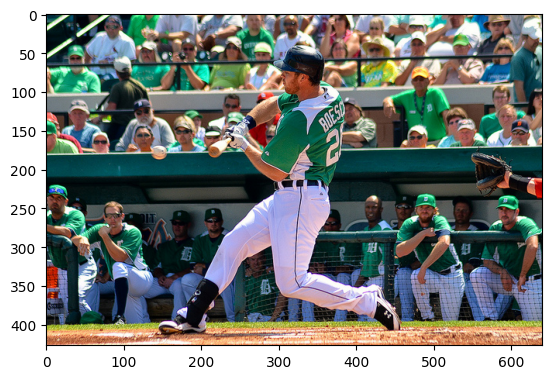

In [158]:
img = to_pil(read_image(meta['image']))
plt.imshow(img)
plt.show()

In [159]:
target

array([[169, 145],
       [180, 129],
       [151, 138],
       [219, 126],
       [143, 152],
       [270, 163],
       [141, 216],
       [349, 257],
       [ 44, 268],
       [  0,   0],
       [ 57, 284],
       [340, 407],
       [255, 431],
       [  0,   0],
       [  0,   0],
       [  0,   0],
       [  0,   0]])

## 확인한 점

- target이 256x192를 넘어가는걸 보니까, 해당 target 값은 원본에서의 keypoint 좌표값으로 보인다.
- bbox를 어떻게 자른건지 궁금하다. (annotation data에 있는 bbox보다는 넓은 느낌이다.)
- rotation으로 인해 padding이 생기면 그냥 패딩을 안고 가는 형태다.